# Table Basics and Merging DataFrames

## Use of AI: can be used, but must be reported.
## AI shall not be used to complete the whole assignment.

In [55]:
# Take libraries in use
import pandas as pd
import numpy as np
import matplotlib as mp
import matplotlib.pyplot as plt
import seaborn as sns

## Read data to DataFrame

In [56]:
df = sns.load_dataset('taxis')
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [57]:
df.describe()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,6433,6433,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,2019-03-16 08:31:28.514223,2019-03-16 08:45:49.491216,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,2019-03-08 15:50:34,2019-03-08 16:12:51,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,2019-03-15 21:46:58,2019-03-15 22:06:44,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2019-03-23 17:41:38,2019-03-23 17:51:56,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000
std,NaN,NaN,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570


In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [59]:
# remove rows with null values
df = df.dropna()
df.info()

<class 'pandas.DataFrame'>
Index: 6341 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6341 non-null   datetime64[us]
 1   dropoff          6341 non-null   datetime64[us]
 2   passengers       6341 non-null   int64         
 3   distance         6341 non-null   float64       
 4   fare             6341 non-null   float64       
 5   tip              6341 non-null   float64       
 6   tolls            6341 non-null   float64       
 7   total            6341 non-null   float64       
 8   color            6341 non-null   str           
 9   payment          6341 non-null   str           
 10  pickup_zone      6341 non-null   str           
 11  dropoff_zone     6341 non-null   str           
 12  pickup_borough   6341 non-null   str           
 13  dropoff_borough  6341 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)
memor

### Create tables using data

In [60]:
df.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='str')

## Cross-tabulation with Pandas
- https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html

In [61]:
# Default
# pandas.crosstab(index, columns, values=None, rownames=None, colnames=None,
#                aggfunc=None, margins=False, margins_name='All',
#                dropna=True, normalize=False)

In [62]:
# Cross-tabulating table with orginal variable names
pd.crosstab(df['pickup_borough'],df['payment'],
            margins=True, margins_name="Total") # the indices are group by names in pickup_borough columns
# df['payment']: counts the payment method by cash or credit
# margins = True: add Subtotal, 
# add margisn_name
# result: total COUNTS

payment,cash,credit card,Total
pickup_borough,,,
Bronx,25,74,99
Brooklyn,118,260,378
Manhattan,1394,3832,5226
Queens,258,380,638
Total,1795,4546,6341


In [63]:
# Change the names of row and column titles
pd.crosstab(df['pickup_borough'],df['payment'],
            rownames =['Pickup place'], colnames = ['Payment method'],
            margins=True, margins_name="Total")

Payment method,cash,credit card,Total
Pickup place,,,
Bronx,25,74,99
Brooklyn,118,260,378
Manhattan,1394,3832,5226
Queens,258,380,638
Total,1795,4546,6341


In [64]:
# Show values as fractions
# normalize based on 'index', when total per row = 1.0
# option is to normalize per 'columns'
pd.crosstab(df['pickup_borough'],df['payment'],
            rownames =['Pickup place'], colnames = ['Payment method'],
            normalize = 'index',
            margins=True, margins_name="Total")


Payment method,cash,credit card
Pickup place,,
Bronx,0.252525,0.747475
Brooklyn,0.312169,0.687831
Manhattan,0.266743,0.733257
Queens,0.404389,0.595611
Total,0.283078,0.716922


In [65]:
# Show values as % by multiplying result with 100
(pd.crosstab(df['pickup_borough'],df['payment'],
            rownames =['Pickup place'], colnames = ['Payment method'],
            normalize = 'index',
            margins=True, margins_name="Total")*100).round(2)

Payment method,cash,credit card
Pickup place,,
Bronx,25.25,74.75
Brooklyn,31.22,68.78
Manhattan,26.67,73.33
Queens,40.44,59.56
Total,28.31,71.69


In [66]:
# check variable names
df.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='str')

In [67]:
# Use more variables in cross-tabulation
pd.crosstab([df['pickup_borough'], df['payment']], df['dropoff_borough'],
            rownames=['Pickup place', 'Payment method'], colnames=['Dropoff place'],
            margins=True, margins_name="Total")
# df['pickup_borough']: group by 'pickup_borough'
# df['payment']] then group by 'payment'
# df['dropoff_borough']: the last one should be understood as group by columns

Dropoff place                Bronx  Brooklyn  Manhattan  Queens  \
Pickup place Payment method                                       
Bronx        cash               21         0          4       0   
             credit card        45         4         21       4   
Brooklyn     cash                0       104         11       3   
             credit card         5       176         56      23   
Manhattan    cash               27        35       1298      34   
             credit card        27       116       3559     128   
Queens       cash                4        14         47     193   
             credit card         7        48        176     149   
Total                          136       497       5172     534   

Dropoff place                Staten Island  Total  
Pickup place Payment method                        
Bronx        cash                        0     25  
             credit card                 0     74  
Brooklyn     cash                        0    118  
             credit card                 0    260  
Manhattan    cash                        0   1394  
             credit card                 2   3832  
Queens       cash                        0    258  
             credit card                 0    380  
Total                                    2   6341

## Pivot table

### Cross-tabulation using Pivot table
https://pandas.pydata.org/docs/reference/api/pandas.pivot_table.html

In [68]:
# default
# pandas.pivot_table(data, values=None, index=None, columns=None,
#                   aggfunc='mean', fill_value=None, margins=False,
#                   dropna=True, margins_name='All', observed=<no_default>, sort=True)


In [69]:
# Show pivot table for variables with default (i.e. aggfunc = 'mean')
# Parameter "values" define
pd.pivot_table(df, values='passengers',
               index=['pickup_borough'])
# aggfunc = 'mean'

,passengers
pickup_borough,
Bronx,1.191919
Brooklyn,1.314815
Manhattan,1.569269
Queens,1.528213


In [70]:
# use aggfunc "sum" to get frequency
pd.pivot_table(df, values='passengers',
               index=['pickup_borough'],
               aggfunc="sum")

,passengers
pickup_borough,
Bronx,118
Brooklyn,497
Manhattan,8201
Queens,975


In [71]:
#  One variable in row and another in column
pd.pivot_table(df, values='passengers',
               index=['pickup_borough'],
               columns=['dropoff_borough'],
               aggfunc="sum")

dropoff_borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
pickup_borough,,,,,
Bronx,84.0,4.0,26.0,4.0,NaN
Brooklyn,7.0,354.0,101.0,35.0,NaN
Manhattan,70.0,223.0,7634.0,272.0,2.0
Queens,15.0,106.0,348.0,506.0,NaN


In [72]:
# fill NaN values with 0
#  One variable in row and another in column
pd.pivot_table(df, values='passengers',
               index=['pickup_borough'],
               columns=['dropoff_borough'],
               fill_value = 0,
               aggfunc="sum")

dropoff_borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
pickup_borough,,,,,
Bronx,84,4,26,4,0
Brooklyn,7,354,101,35,0
Manhattan,70,223,7634,272,2
Queens,15,106,348,506,0


In [73]:
# present several aggfunctions is result
df.pivot_table(values='passengers', index=['pickup_borough', 'dropoff_borough'],
                   aggfunc=['min', 'mean','median', 'max'])

min       mean     median        max
                               passengers passengers passengers passengers
pickup_borough dropoff_borough                                            
Bronx          Bronx                    1   1.272727        1.0          5
               Brooklyn                 1   1.000000        1.0          1
               Manhattan                0   1.040000        1.0          2
               Queens                   1   1.000000        1.0          1
Brooklyn       Bronx                    1   1.400000        1.0          3
               Brooklyn                 0   1.264286        1.0          6
               Manhattan                1   1.507463        1.0          6
               Queens                   1   1.346154        1.0          6
Manhattan      Bronx                    1   1.296296        1.0          5
               Brooklyn                 0   1.476821        1.0          6
               Manhattan                0   1.571752        1.0          6
               Queens                   0   1.679012        1.0          6
               Staten Island            1   1.000000        1.0          1
Queens         Bronx                    1   1.363636        1.0          5
               Brooklyn                 0   1.709677        1.0          6
               Manhattan                0   1.560538        1.0          6
               Queens                   0   1.479532        1.0          6

In [74]:
# use same precision for all data (no decimals)
# use .style.format(precision=0)
df.pivot_table(values='passengers', index=['pickup_borough', 'dropoff_borough'],
                   aggfunc=['min', 'median', 'max']).style.format(precision=0)

In [75]:
# Highlight maximum and minimum values
df.pivot_table(values='passengers', index=['pickup_borough', 'dropoff_borough'],
                   aggfunc=['min', 'median', 'max']).style.format(precision=0)\
                    .highlight_max(color='green', axis=0)\
                    .highlight_min(color='blue', axis=0)

## Frequency and Percentage distributions in table
- use crosstab() to calculate values
- https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html

In [76]:
# Create DataFrame to include the data
pd.crosstab(df['pickup_borough'], 'Freq')

col_0,Freq
pickup_borough,
Bronx,99
Brooklyn,378
Manhattan,5226
Queens,638


In [77]:
# Modify row and column names
pd.crosstab(df['pickup_borough'], 'Freq',
            rownames =['Pickup place'], colnames = [''])

,Freq
Pickup place,
Bronx,99
Brooklyn,378
Manhattan,5226
Queens,638


## Data formatting
- https://pandas.pydata.org/docs/reference/api/pandas.io.formats.style.Styler.format.html

In [78]:
# Store the result in new DataFrame for formatting
df1 = pd.crosstab(df['pickup_borough'], 'Freq',
            rownames =['Pickup place'], colnames = [''])
df1

,Freq
Pickup place,
Bronx,99
Brooklyn,378
Manhattan,5226
Queens,638


In [79]:
# count sum and values for percentages
n = df1['Freq'].sum() # count total sum
df1['%'] = df1['Freq']/n*100 # Count % value and add new column
df1

,Freq,%
Pickup place,,
Bronx,99,1.561268
Brooklyn,378,5.961205
Manhattan,5226,82.416023
Queens,638,10.061504


In [80]:
# Create format for data
format = {'Freq':'{:.0f}', '%':'{:.1f} %'}
# present table using the format
df1.style.format(format)

,Freq,%
Pickup place,,
Bronx,99,1.6 %
Brooklyn,378,6.0 %
Manhattan,5226,82.4 %
Queens,638,10.1 %


## Tasks: Tables

Load data of 'penguins' using Seaborn.
Then make 3 different tables using the penguins data where
1. table contains frequencies and % of one variable
2. table contains cross-tabulation for two variables using crosstab
3. table contain cross-tabulation for two variables using pivot_table
Pay attention, which would be good variables to select (categorical or numerical, missing values vs. no missing values, etc.)

In [81]:
df0 = sns.load_dataset('penguins')
df0.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [82]:
df1 = pd.crosstab(df0['species'], 'Freq',
            rownames =['Species'], colnames = [''])
df1

,Freq
Species,
Adelie,152
Chinstrap,68
Gentoo,124


In [83]:
# count sum and values for percentages
n = df1['Freq'].sum() # total sum of all counts
df1['%'] = df1['Freq']/n*100 # Count % value and add new column
df1

,Freq,%
Species,,
Adelie,152,44.186047
Chinstrap,68,19.767442
Gentoo,124,36.046512


In [84]:
# Create format for data
format = {'Freq':'{:.0f}', '%':'{:.1f} %'}
# present table using the format
df1.style.format(format)

,Freq,%
Species,,
Adelie,152,44.2 %
Chinstrap,68,19.8 %
Gentoo,124,36.0 %


# Join and Merge

* When joining two dataframes, we need to make a difference between the left and right dataframe.


In [85]:
# Left DataFrame
df1 = pd.DataFrame({
    'name': ['Dolly', 'Jaws', 'Thunder', 'Kitty', 'Cujo'],
    'species': ['sheep', 'shark', 'horse', 'cat', 'dog']
}, index = [1, 2, 3, 4, 5])

# Right DataFrame
df2 = pd.DataFrame({
    'offspring': ['pup', 'foal', 'kitten', 'pup', 'joey']
}, index = [2, 3, 4, 5, 6])

print(df1)
print(df2)

      name species
1    Dolly   sheep
2     Jaws   shark
3  Thunder   horse
4    Kitty     cat
5     Cujo     dog
  offspring
2       pup
3      foal
4    kitten
5       pup
6      joey


## Left Join

In [86]:
# Left join (default), it is done on index
df1.join(df2) # ONLY LEFT

,name,species,offspring
1,Dolly,sheep,NaN
2,Jaws,shark,pup
3,Thunder,horse,foal
4,Kitty,cat,kitten
5,Cujo,dog,pup



Notice how there is a Nan value at line 1 and index 6 of df2 is not included in left join.



## Right Join

In [87]:
# Right join
df1.join(df2, how = 'right') # ONLY RIGHT

,name,species,offspring
2,Jaws,shark,pup
3,Thunder,horse,foal
4,Kitty,cat,kitten
5,Cujo,dog,pup
6,NaN,NaN,joey



Notice how right join used all indexes of the right data frame and not the index 1 (that exists only in the left df).



## Inner Join

In [88]:
# Innder join
df1.join(df2, how = 'inner') # AND BOTH

,name,species,offspring
2,Jaws,shark,pup
3,Thunder,horse,foal
4,Kitty,cat,kitten
5,Cujo,dog,pup


Inner join only keeps rows with matching indexes in both DataFrames.

## Outer Join

In [89]:
# Outer join (on index)
df1.join(df2, how = 'outer') # EITHER OR

,name,species,offspring
1,Dolly,sheep,NaN
2,Jaws,shark,pup
3,Thunder,horse,foal
4,Kitty,cat,kitten
5,Cujo,dog,pup
6,NaN,NaN,joey


Outer join keeps all rows and fills missing values with NaN

## Merge

In [90]:
# Left DataFrame
df3 = pd.DataFrame({
    'id': [1, 2, 3, 4, 5],
    'name': ['Dolly', 'Jaws', 'Thunder', 'Kitty', 'Cujo'],
    'species': ['sheep', 'shark', 'horse', 'cat', 'dog']
})

# Right DataFrame
df4 = pd.DataFrame({
    'id': [2, 3, 4, 5, 6],
    'offspring': ['pup', 'foal', 'kitten', 'pup', 'joey']
})

print(df3)
print(df4)

   id     name species
0   1    Dolly   sheep
1   2     Jaws   shark
2   3  Thunder   horse
3   4    Kitty     cat
4   5     Cujo     dog
   id offspring
0   2       pup
1   3      foal
2   4    kitten
3   5       pup
4   6      joey


In [91]:
# In merge, inner join is default.

pd.merge(df3, df4, on = 'id')

,id,name,species,offspring
0,2,Jaws,shark,pup
1,3,Thunder,horse,foal
2,4,Kitty,cat,kitten
3,5,Cujo,dog,pup


In [92]:
# Left Join
# Keeps all the rows from the left DataFrame, matching from the right where possible.

pd.merge(df3, df4, on = 'id', how = 'left')

,id,name,species,offspring
0,1,Dolly,sheep,NaN
1,2,Jaws,shark,pup
2,3,Thunder,horse,foal
3,4,Kitty,cat,kitten
4,5,Cujo,dog,pup


In [93]:
# Right Join
# Keeps all the rows from the right DataFrame.

pd.merge(df3, df4, on = 'id', how = 'right')

,id,name,species,offspring
0,2,Jaws,shark,pup
1,3,Thunder,horse,foal
2,4,Kitty,cat,kitten
3,5,Cujo,dog,pup
4,6,NaN,NaN,joey


In [94]:
# Outer Join
# Keeps all the rows from both, filling in NaN where there’s no match.

pd.merge(df3, df4, on = 'id', how = 'outer')

,id,name,species,offspring
0,1,Dolly,sheep,NaN
1,2,Jaws,shark,pup
2,3,Thunder,horse,foal
3,4,Kitty,cat,kitten
4,5,Cujo,dog,pup
5,6,NaN,NaN,joey


## Tasks: Merge + some more Pandas

Use the given dataframes (as they are). 
Show the dataframe(s) after every step.

1. Merge df1 and df2 (using merge, not join()) so that all rows from both data frames are included, save the merged dataframe into df3.
* Notice that in merge the planets get sorted alphabetically.
2. Change the distance_from_earth_million_km column's name to distance.
3. Let's say that there is a blunder in the data and after merging the dataframe you notice that the number of moons is totally wrong. Fix them into the merged dataframe. Correct numbers of moons is found here: https://spaceplace.nasa.gov/how-many-moons/en/
* Show df3 and verify, that now the number of moons is correct.
4. Change NaN into 0 (or 0.0)
5. Add a column named moon-% and count the percentage of moons each planet has (moons of the planet / total number of moons) * 100%. Show df3.
6. Create a pie chart (use matplotlib's .pie -function) from the moons column
* Use autopct -parameter so that the pie chart includes the percentage automatically.
7. What are the differences and similarities of Pandas join() and merge()? Add your answer to a markdown/text cell after the pie chart.



In [95]:
# Do not change this code.

# Left data frame
df1 = pd.DataFrame({
    'planet': ['Mercury', 'Venus', 'Earth', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune'],
    'type': ['Terrestrial', 'Terrestrial', 'Terrestrial', 'Terrestrial', 'Gas Giant', 'Gas Giant', 'Ice Giant', 'Ice Giant']
})

# Right data frame (do not fix the number of moons quite yet).
df2 = pd.DataFrame({
    'planet': ['Mercury', 'Venus', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune'],
    'distance_from_earth_million_km': [77, 41, 78, 628, 1275, 2720, 4350],
    'moons': [0, 100, 42, 220, 1045, 15, 'NaN']
})

print(df1)
print("\n",df2)

    planet         type
0  Mercury  Terrestrial
1    Venus  Terrestrial
2    Earth  Terrestrial
3     Mars  Terrestrial
4  Jupiter    Gas Giant
5   Saturn    Gas Giant
6   Uranus    Ice Giant
7  Neptune    Ice Giant

     planet  distance_from_earth_million_km moons
0  Mercury                              77     0
1    Venus                              41   100
2     Mars                              78    42
3  Jupiter                             628   220
4   Saturn                            1275  1045
5   Uranus                            2720    15
6  Neptune                            4350   NaN


### 1. Merge df1 and df2 (using merge, not join()) so that all rows from both data frames are included, save the merged dataframe into df3.
* Notice that in merge the planets get sorted alphabetically.

In [96]:
df3 = df1.merge(df2, on='planet',how='outer')
df3

,planet,type,distance_from_earth_million_km,moons
0,Earth,Terrestrial,NaN,NaN
1,Jupiter,Gas Giant,628.0,220
2,Mars,Terrestrial,78.0,42
3,Mercury,Terrestrial,77.0,0
4,Neptune,Ice Giant,4350.0,NaN
5,Saturn,Gas Giant,1275.0,1045
6,Uranus,Ice Giant,2720.0,15
7,Venus,Terrestrial,41.0,100


### 2. Change the distance_from_earth_million_km column's name to distance.

In [97]:
df3.rename(columns={'distance_from_earth_million_km':'distance'},inplace=True) # inplace = True: change directly to df3 without re-assigning
df3

,planet,type,distance,moons
0,Earth,Terrestrial,NaN,NaN
1,Jupiter,Gas Giant,628.0,220
2,Mars,Terrestrial,78.0,42
3,Mercury,Terrestrial,77.0,0
4,Neptune,Ice Giant,4350.0,NaN
5,Saturn,Gas Giant,1275.0,1045
6,Uranus,Ice Giant,2720.0,15
7,Venus,Terrestrial,41.0,100


### 3. Let's say that there is a blunder in the data and after merging the dataframe you notice that the number of moons is totally wrong. Fix them into the merged dataframe. Correct numbers of moons is found here: https://spaceplace.nasa.gov/how-many-moons/en/
* Show df3 and verify, that now the number of moons is correct:

Earth	1. 
Jupiter	115. 
Mars	2. 
Mercury	0. 
Neptune	16. 
Saturn	293. 
Uranus	29. 
Venus	0


In [98]:
correct_moon = {
'Earth':1,
'Jupiter':115,
'Mars':2,
'Mercury':0,
'Neptune':16,
'Saturn':293,
'Uranus':29,
'Venus':0
                } # make a dictionary of correct_moon replace the old values in columns moons with new numbers in Dictionary
df3['moons']=df3['planet'].replace(correct_moon)
df3

,planet,type,distance,moons
0,Earth,Terrestrial,NaN,1
1,Jupiter,Gas Giant,628.0,115
2,Mars,Terrestrial,78.0,2
3,Mercury,Terrestrial,77.0,0
4,Neptune,Ice Giant,4350.0,16
5,Saturn,Gas Giant,1275.0,293
6,Uranus,Ice Giant,2720.0,29
7,Venus,Terrestrial,41.0,0


### 4. Change NaN into 0 (or 0.0)

In [99]:
df3=df3.fillna(0) # Notes: 'NaN' is not a normal text/string in the dateframe.
# Therefore, Can not do this: df3['distance']=df3['distance'].str.replace('NaN','')
df3

,planet,type,distance,moons
0,Earth,Terrestrial,0.0,1
1,Jupiter,Gas Giant,628.0,115
2,Mars,Terrestrial,78.0,2
3,Mercury,Terrestrial,77.0,0
4,Neptune,Ice Giant,4350.0,16
5,Saturn,Gas Giant,1275.0,293
6,Uranus,Ice Giant,2720.0,29
7,Venus,Terrestrial,41.0,0


### 5. Add a column named moon-% and count the percentage of moons each planet has (moons of the planet / total number of moons) * 100%. Show df3.

In [100]:
# total moons:
total_moon = df3['moons'].sum()
# add cloumn %:
df3['%']=(df3['moons']/total_moon)*100
df3

,planet,type,distance,moons,%
0,Earth,Terrestrial,0.0,1,0.219298
1,Jupiter,Gas Giant,628.0,115,25.219298
2,Mars,Terrestrial,78.0,2,0.438596
3,Mercury,Terrestrial,77.0,0,0.0
4,Neptune,Ice Giant,4350.0,16,3.508772
5,Saturn,Gas Giant,1275.0,293,64.254386
6,Uranus,Ice Giant,2720.0,29,6.359649
7,Venus,Terrestrial,41.0,0,0.0


In [101]:
# Create format for data
# format = {'moons':'{:.0f}', '%':'{:.2f} %'}
# present table using the format
# df3.style.format(format)

### 6. Create a pie chart (use matplotlib's .pie -function) from the moons column
* Use autopct -parameter so that the pie chart includes the percentage automatically.

In [ ]:
df3.info()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   planet    8 non-null      str    
 1   type      8 non-null      str    
 2   distance  8 non-null      float64
 3   moons     8 non-null      object 
 4   %         8 non-null      object 
dtypes: float64(1), object(2), str(2)
memory usage: 452.0+ bytes


In [107]:
# turn moons into numeric instead of 'object' datatype
df3['moons'] = pd.to_numeric(df3['moons'])
df3.info()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   planet    8 non-null      str    
 1   type      8 non-null      str    
 2   distance  8 non-null      float64
 3   moons     8 non-null      int64  
 4   %         8 non-null      object 
dtypes: float64(1), int64(1), object(1), str(2)
memory usage: 452.0+ bytes


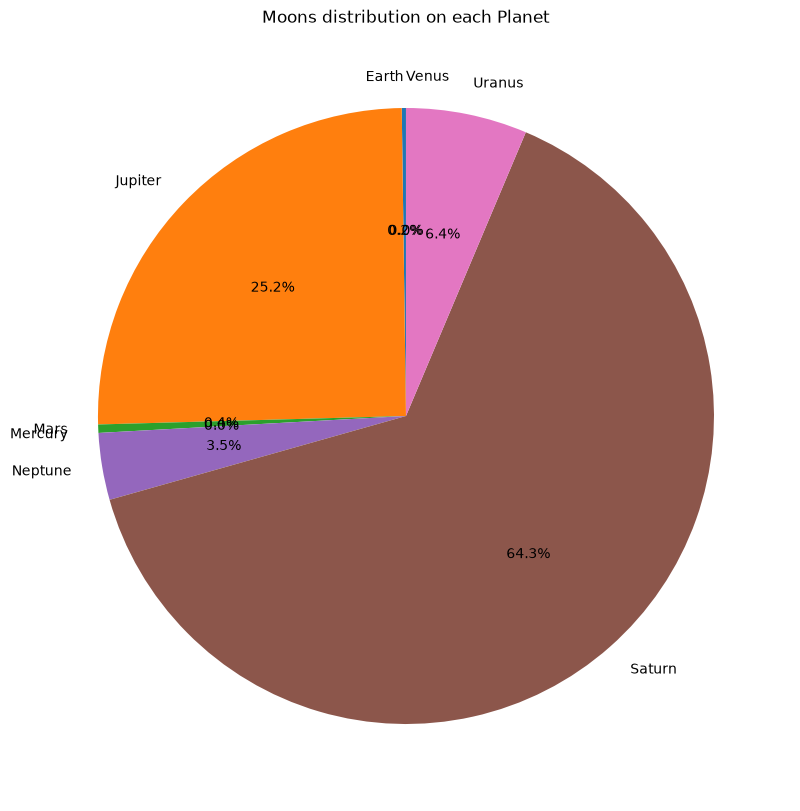

In [111]:
fig, ax = plt.subplots(figsize=(10,10)) # call pie chart and size of the chart
ax.pie(df3['moons'], labels=df3['planet'], autopct='%1.1f%%', startangle=90) # take moons figure, lable shall be based on Planet names,, start Angle = 90
ax.set_title('Moons distribution on each Planet')
plt.show()


## Task: AI statement (mandatory)

Describe here, how did you use AI in this assignment (or mention, if you did not use it at all):
* used to explain some codes

## Task return

File > Save and Export Notebook As > HTML

Then take a look the produced HTML that it looks ok and readable

Return to Itslearning, only the html document is returned, *not the .ipynb